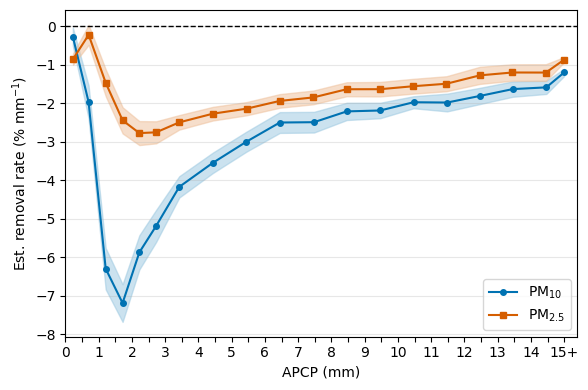

In [5]:
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
mpl.rcParams.update(mpl.rcParamsDefault)
pm10 = pd.read_csv(
    r"\results\pm10\PM10_removal_by_precipitation.csv"
)
pm25 = pd.read_csv(
    r"\results\pm25\PM25_removal_by_precipitation.csv"
)
PM25_DARK, PM10_DARK = "#D55E00", "#0072B2"
PM25_LIGHT50, PM10_LIGHT50 = "#EEBF99", "#99C7E0"

pm10["pollutant"] = "PM10"
pm25["pollutant"] = "PM2.5"

df_plot = pd.concat([pm10, pm25], ignore_index=True)

styles = {
    "PM10": dict(
        color=PM10_DARK,
        ci=PM10_LIGHT50,
        marker="o",
        label=r"PM$_{10}$"
    ),
    "PM2.5": dict(
        color=PM25_DARK,
        ci=PM25_LIGHT50,
        marker="s",
        label=r"PM$_{2.5}$"
    ),
}

fig, ax = plt.subplots(figsize=(6, 4))

for pollutant, group in df_plot.groupby("pollutant"):
    s = styles[pollutant]

    group = group.sort_values("median_APCP").reset_index(drop=True)

    x = group["median_APCP"].astype(float).values

    x_plot = np.minimum(x, 15.0)

    y = group["theta"].astype(float).values
    lo = group["theta_ci_low"].astype(float).values
    hi = group["theta_ci_high"].astype(float).values

    # Confidence interval
    ax.fill_between(
        x_plot,
        lo,
        hi,
        color=s["ci"],
        alpha=0.5
    )

    # Line with markers
    ax.plot(
        x_plot,
        y,
        marker=s["marker"],
        color=s["color"],
        linestyle="-",
        linewidth=1.5,
        markersize=4,
        zorder=3,
        label=s["label"]
    )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

xticks = np.arange(0, 15.5, 0.5)
ax.set_xticks(xticks)

def tick_fmt(x, pos):
    if np.isclose(x, 15.0):
        return "15+"
    elif np.isclose(x % 1, 0):
        return f"{int(x)}"
    return ""

ax.xaxis.set_major_formatter(FuncFormatter(tick_fmt))

ax.set_xlim(0, 15.4)

ax.set_ylabel(r"Est. removal rate (% mm$^{-1}$)")
ax.set_xlabel(r"APCP (mm)")

ax.legend()
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()

plt.savefig(
    r"\figures\theta_by_precipitation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()